# General relativity 2: The equivalence principle

*Learning path: general relativity, part 2 of 9.* [Index](README.md) · Previous: [Spacetime](01-spacetime.ipynb) · Next: [Einstein's equations](03-einstein-equations.ipynb)

In 1907 Einstein had "the happiest thought of my life" [1][2]: a person falling freely does not feel their own weight. Gravity
can be made to disappear, locally, by falling with it. This notebook follows that idea to the conclusion that gravity is
geometry. You will learn

* why an accelerating rocket is indistinguishable from a gravitational field,
* that such a field can be produced in flat spacetime just by changing coordinates,
* how Newton's law of gravity comes out of the time part of the metric,
* why clocks run slower lower down, and why tides are the real signature of curvature.

## 1. Gravity in a rocket

A rocket accelerating at $g$ far from any star: everything inside "falls" to the floor at $g$, exactly as on Earth. The
spacetime is still flat Minkowski space; only the coordinates, those of the accelerating crew, are new. In the crew's
coordinates (the *Rindler* coordinates, for small heights $x$ above the floor),

$$ds^2 = -(1 + g x)^2\,dt^2 + dx^2$$

In [1]:
rindler = metric([t x], [-(1+g*x)^2 0; 0 1])
riemannsecond(rindler)

$$ds^2 = -\left(g \, x + 1\right)^{2}\, dt^2 + dx^2$$

**Riemann curvature tensor** (coordinates $t$, $x$)

$$\begin{aligned}
R = 0 \quad\text{(all components)}
\end{aligned}$$

The Riemann tensor is zero: no curvature at all. Yet the Christoffel symbols are not zero:

In [2]:
christoffel(rindler)

**Christoffel symbols of the second kind** (coordinates $t$, $x$)

$$\begin{aligned}
\Gamma{}^{t}{}_{t}{}_{x} &= \frac{g}{g \, x + 1} \\
\Gamma{}^{x}{}_{t}{}_{t} &= g \, \left(g \, x + 1\right)
\end{aligned}$$

The geodesic equation gives $\ddot x = -\Gamma^x{}_{tt}\,\dot t^2 \approx -g$: free objects fall towards the floor.
Drop a ball at height 1 with $g = 1$, and draw height against time:

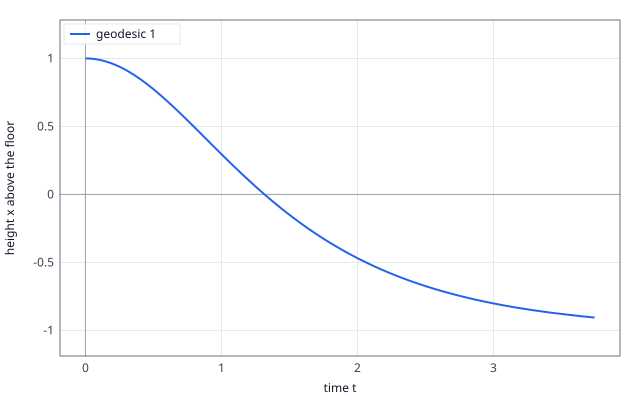

In [3]:
g = 1;
labels(geodesic(rindler, [0 1], [1 0], 1.2, [t x]), "time t", "height x above the floor")

So a "gravitational field" can be nothing but the coordinates of an accelerating observer, carried by the
Christoffel symbols. This is the **equivalence principle**: locally, gravity and acceleration cannot be told apart.

## 2. Newton from the metric

Near a planet of mass $M$ and for slow motion, the metric is approximately

$$ds^2 = -\left(1 - \frac{2GM}{r}\right)dt^2 + dr^2 + r^2\,d\Omega^2$$

(with $c = 1$; $-GM/r$ is the Newtonian potential). Its Christoffel symbols:

In [4]:
clear
weak = metric([t r theta phi], [-(1-2*G*M/r) 0 0 0; 0 1 0 0; 0 0 r^2 0; 0 0 0 r^2*sin(theta)^2])
christoffel(weak)

$$ds^2 = \frac{2 \, G \, M - r}{r}\, dt^2 + dr^2 + r^{2}\, d\theta^2 + r^{2} \, \sin^{2}\left(\theta\right)\, d\phi^2$$

**Christoffel symbols of the second kind** (coordinates $t$, $r$, $\theta$, $\phi$)

$$\begin{aligned}
\Gamma{}^{t}{}_{t}{}_{r} &= \frac{G \, M}{r \, \left(r - 2 \, G \, M\right)} \\
\Gamma{}^{r}{}_{t}{}_{t} &= \frac{G \, M}{r^{2}} \\
\Gamma{}^{r}{}_{\theta}{}_{\theta} &= -r \\
\Gamma{}^{r}{}_{\phi}{}_{\phi} &= -r \, \sin^{2}\left(\theta\right) \\
\Gamma{}^{\theta}{}_{r}{}_{\theta} &= \frac{1}{r} \\
\Gamma{}^{\theta}{}_{\phi}{}_{\phi} &= -\sin\left(\theta\right) \, \cos\left(\theta\right) \\
\Gamma{}^{\phi}{}_{r}{}_{\phi} &= \frac{1}{r} \\
\Gamma{}^{\phi}{}_{\theta}{}_{\phi} &= \frac{\cos\left(\theta\right)}{\sin\left(\theta\right)}
\end{aligned}$$

$\Gamma^r{}_{tt} = GM/r^2$. For a slowly moving object $\dot t \approx 1$, so the geodesic equation says

$$\ddot r = -\Gamma^r{}_{tt} = -\frac{GM}{r^2}$$

**Newton's law of gravitation**, from nothing but the $g_{tt}$ part of the metric. Gravity, for everyday purposes, is
the fact that time runs at different rates at different heights.

## 3. Clocks run slower lower down

A clock at rest at radius $r$ has $d\tau = \sqrt{1 - 2GM/(rc^2)}\;dt$: the deeper in the potential, the slower it
ticks. On the Earth's surface the effect is about 7 parts in $10^{10}$, which adds up to roughly 22 milliseconds per
year compared with a clock far away:

In [5]:
GMe = 3.986004418e14;
c = 299792458;
Re = 6.371e6;
eval(GMe/(Re*c^2))
eval(GMe/(Re*c^2)*365.25*86400*1000)

6.961274586591854e-10
21.96811188938311

Clocks this good exist: optical atomic clocks measured the difference over a height change of 33 cm in
2010 [3]. Part 7 shows why GPS has to correct for it.

## 4. What cannot be transformed away: tides

The equivalence principle is local. A freely falling lab that is large enough sees two dropped balls side by side drift
together (both fall towards the Earth's centre) and two balls one above the other drift apart. These **tidal** effects
cannot be removed by any choice of coordinates. They are the curvature: the Riemann tensor, which is exactly zero for
the rocket but not for a planet.

The full spacetime outside a spherical mass is the Schwarzschild metric (part 4). Its Riemann tensor shows the tide:

In [6]:
S = metric.generate(schwarzschild)
riemannsecond(S)

$$ds^2 = -\frac{r - r_{s}}{r}\, dt^2 + \frac{r}{r - r_{s}}\, dr^2 + r^{2}\, d\theta^2 + r^{2} \, \sin^{2}\left(\theta\right)\, d\phi^2$$

**Riemann curvature tensor** (coordinates $t$, $r$, $\theta$, $\phi$)

$$\begin{aligned}
R{}^{t}{}_{r}{}_{t}{}_{r} &= \frac{r_{s}}{r^{2} \, \left(r - r_{s}\right)} \\
R{}^{t}{}_{\theta}{}_{t}{}_{\theta} &= -\frac{r_{s}}{2 \, r} \\
R{}^{t}{}_{\phi}{}_{t}{}_{\phi} &= -\frac{r_{s} \, \sin^{2}\left(\theta\right)}{2 \, r} \\
R{}^{r}{}_{t}{}_{t}{}_{r} &= \frac{r_{s} \, \left(r - r_{s}\right)}{r^{4}} \\
R{}^{r}{}_{\theta}{}_{r}{}_{\theta} &= -\frac{r_{s}}{2 \, r} \\
R{}^{r}{}_{\phi}{}_{r}{}_{\phi} &= -\frac{r_{s} \, \sin^{2}\left(\theta\right)}{2 \, r} \\
R{}^{\theta}{}_{t}{}_{t}{}_{\theta} &= \frac{r_{s} \, \left(r_{s} - r\right)}{2 \, r^{4}} \\
R{}^{\theta}{}_{r}{}_{r}{}_{\theta} &= \frac{r_{s}}{2 \, r^{2} \, \left(r - r_{s}\right)} \\
R{}^{\theta}{}_{\phi}{}_{\theta}{}_{\phi} &= \frac{r_{s} \, \sin^{2}\left(\theta\right)}{r} \\
R{}^{\phi}{}_{t}{}_{t}{}_{\phi} &= \frac{r_{s} \, \left(r_{s} - r\right)}{2 \, r^{4}} \\
R{}^{\phi}{}_{r}{}_{r}{}_{\phi} &= \frac{r_{s}}{2 \, r^{2} \, \left(r - r_{s}\right)} \\
R{}^{\phi}{}_{\theta}{}_{\theta}{}_{\phi} &= -\frac{r_{s}}{r}
\end{aligned}$$

For large $r$ the component $R^r{}_{ttr} \approx r_s/r^3 = 2GM/r^3$. The *geodesic deviation equation* says that two
free objects a small distance $\ell$ apart in the radial direction accelerate apart at $R^r{}_{ttr}\,\ell = 2GM\ell/r^3$:
exactly Newton's tidal acceleration, the one that raises two tidal bulges in the oceans [4]. Gravity's honest signature is
curvature.

## Summary

* Free fall cancels gravity locally; an accelerating frame mimics it (the equivalence principle).
* Rindler coordinates produce "gravity" in flat spacetime through the Christoffel symbols alone.
* With $g_{tt} = -(1 + 2\Phi)$, the geodesic equation gives Newton's law $\ddot r = -\nabla\Phi$.
* Clocks run slower deeper in a potential; tides, the Riemann tensor, are what make gravity real.

Next: [Einstein's equations](03-einstein-equations.ipynb), which tell spacetime how to curve.

## Sources

Numbers in square brackets in the text refer to this list.

1. A. Einstein, "Über das Relativitätsprinzip und die aus demselben gezogenen Folgerungen", *Jahrbuch der Radioaktivität und Elektronik* **4**, 411–462 (1907): the first statement of the equivalence principle.
2. A. Pais, *'Subtle is the Lord...': The Science and the Life of Albert Einstein*, Oxford University Press (1982), p. 178, quoting Einstein's 1920 manuscript on "der glücklichste Gedanke meines Lebens".
3. C. W. Chou, D. B. Hume, T. Rosenband and D. J. Wineland, "Optical clocks and relativity", *Science* **329**, 1630–1633 (2010). [doi:10.1126/science.1192720](https://doi.org/10.1126/science.1192720)
4. S. M. Carroll, *Spacetime and Geometry: An Introduction to General Relativity*, Addison-Wesley (2004). Sections 4.1 (Newtonian limit) and 3.10 (geodesic deviation).